<a href="https://colab.research.google.com/github/titarzra/Tugas-MachineLearning_TitaRizekyRahmadina_202343500097/blob/main/Bab_02_Workflow_CRISP_DM_Bias_Variance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Bagian A — Implementasi Python

### Praktikum 2.1 Persiapan Library

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.tree import DecisionTreeClassifier

### Praktikum 2.2 Import Dataset (sintetis, kelas tidak seimbang 80:20)

In [ ]:
X, y = make_classification(n_samples=1000, n_features=10, n_informative=6,
                           weights=[0.8, 0.2], random_state=42)
print("Distribusi kelas:", np.bincount(y))

Distribusi kelas: [797 203]


### Praktikum 2.3 Preprocessing: Stratified Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Proporsi kelas train:", np.bincount(y_train) / len(y_train))
print("Proporsi kelas test :", np.bincount(y_test) / len(y_test))

Proporsi kelas train: [0.7975 0.2025]
Proporsi kelas test : [0.795 0.205]


### Praktikum 2.4 Training Model & Learning Curve

In [ ]:
model = DecisionTreeClassifier(max_depth=4, random_state=42)

train_sizes, train_scores, val_scores = learning_curve(
    model, X_train, y_train, cv=5,
    train_sizes=np.linspace(0.1, 1.0, 8), scoring="accuracy")
train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

### Praktikum 2.5 Evaluasi

In [ ]:
print("Skor train pada ukuran data terbesar :", round(train_mean[-1], 3))
print("Skor validasi pada ukuran data terbesar:", round(val_mean[-1], 3))
print("Gap (indikasi overfitting jika besar)   :", round(train_mean[-1] - val_mean[-1], 3))

Skor train pada ukuran data terbesar : 0.929
Skor validasi pada ukuran data terbesar: 0.885
Gap (indikasi overfitting jika besar)   : 0.044


### Praktikum 2.6 Visualisasi

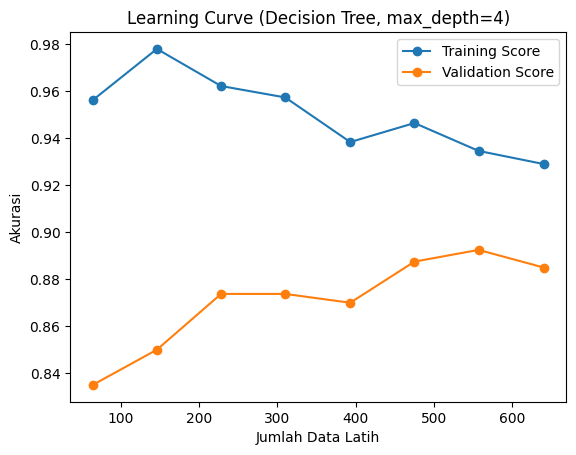

In [ ]:
plt.plot(train_sizes, train_mean, 'o-', label='Training Score')
plt.plot(train_sizes, val_mean, 'o-', label='Validation Score')
plt.xlabel('Jumlah Data Latih')
plt.ylabel('Akurasi')
plt.title('Learning Curve (Decision Tree, max_depth=4)')
plt.legend()
plt.show()

### Praktikum 2 — Diagnosis Bias-Variance (Praktikum 2.7)

Learning curve dibandingkan untuk `max_depth` = 1, 4, dan `None` (pohon tumbuh penuh).

In [ ]:
# Bandingkan learning curve untuk max_depth berbeda (sesuai modul)
for depth in [1, 4, None]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train, y_train, cv=5, train_sizes=np.linspace(0.1, 1.0, 6))
    print(f"max_depth={depth}: train={train_scores.mean():.3f}, val={val_scores.mean():.3f}")

max_depth=1: train=0.849, val=0.800
max_depth=4: train=0.952, val=0.866
max_depth=None: train=1.000, val=0.858


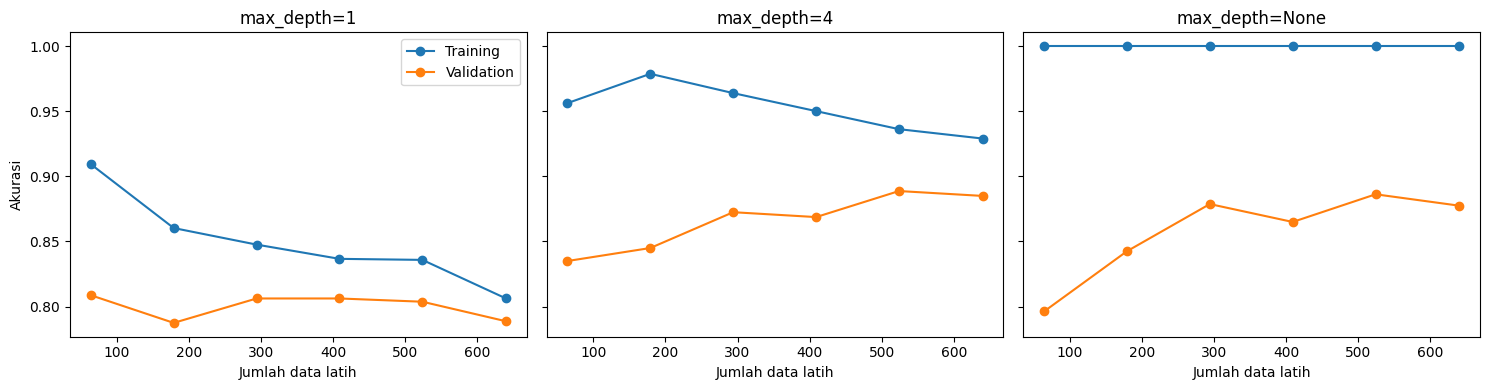

,max_depth,train (n terbesar),validasi (n terbesar),gap
0,1,0.806,0.789,0.017
1,4,0.929,0.885,0.044
2,None,1.000,0.878,0.122


In [ ]:
# Tabel ringkasan pada ukuran data terbesar + visualisasi tiga learning curve berdampingan
baris = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, depth in zip(axes, [1, 4, None]):
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    ts, tr, va = learning_curve(model, X_train, y_train, cv=5,
                                train_sizes=np.linspace(0.1, 1.0, 6), scoring="accuracy")
    tr_m, va_m = tr.mean(axis=1), va.mean(axis=1)
    ax.plot(ts, tr_m, 'o-', label='Training')
    ax.plot(ts, va_m, 'o-', label='Validation')
    ax.set_title(f"max_depth={depth}")
    ax.set_xlabel("Jumlah data latih")
    baris.append({"max_depth": str(depth), "train (n terbesar)": round(tr_m[-1], 3),
                  "validasi (n terbesar)": round(va_m[-1], 3), "gap": round(tr_m[-1] - va_m[-1], 3)})
axes[0].set_ylabel("Akurasi")
axes[0].legend()
plt.tight_layout()
plt.show()
pd.DataFrame(baris)